# Readmission 2026 — Extended Analysis (AACAP)

Tiered inferential analysis on the **complete cohort (N = 2,652 patients; per-patient 90-day (post-discharge)
readmission 9.3%)**, plus a **preliminary-subset** readmission-timing and provider analysis.

**Statistical tiers**
1. **Bivariate inferential** — each association with an explicit test + figure
2. **Subgroup descriptive** — diagnosis subgroups (visit / chronic / non-suicidal) vs four outcomes
3. **Multivariate inferential** — adjusted logistic & linear regression
4. **Readmission windows & readmission LOS** — *preliminary subset* (XLSX, N≈1,920; 1,206 linked)
5. **Psychiatrist vs NP** — *preliminary subset*, exploratory (n=26 NP)
6. **ML / predictive** — Random Forest & CatBoost with new features

> Tests follow the project's idioms: Mann-Whitney U (skewed LOS / continuous-by-group), Spearman
> (continuous-continuous), chi-square (categorical), Kruskal-Wallis (>2 groups), `statsmodels`
> logistic/OLS for adjusted models. Multi-hypothesis families are FDR (Benjamini-Hochberg) corrected.
> LOS is right-skewed, so medians (IQR) and non-parametric tests are primary.


In [1]:
# ── Imports & style ──────────────────────────────────────────────────────────
import warnings; warnings.filterwarnings('ignore')
import os, json
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

plt.rcParams.update({'font.size':12,'axes.titlesize':14,'figure.dpi':120,'savefig.dpi':200,'savefig.bbox':'tight'})
BLUE, ORANGE, GREEN, RED, PURPLE = '#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3'
sns.set_style('whitegrid')
os.makedirs('figures', exist_ok=True)
ROOT = '.'
print('✓ libraries loaded')

✓ libraries loaded


## Preamble — load complete cohort & engineer features
(mirrors Part 1; this notebook stands alone)

In [ ]:
# ── Load complete cohort (N=2,652) + feature engineering ─────────────────────
df = pd.read_csv('data/annotated_psychiatric_data_complete.csv')
df['readmitted'] = (pd.to_numeric(df['Readmissions'], errors='coerce').fillna(0) > 0).astype(int)
df['age'] = pd.to_numeric(df['Pt_Age_Visit'], errors='coerce')
df['gender'] = df['GenderCode'].str.strip().str.title()
df['gender_male'] = (df['GenderCode'].str.strip().str.lower()=='male').astype(int)
df['insurance_public'] = df['Insurance'].str.contains('AHCCCS', case=False, na=False).astype(int)
df['insurance_cat'] = np.where(df['insurance_public']==1,'Public (AHCCCS)','Commercial/Other')
df['ace_score'] = pd.to_numeric(df['ACEscore'], errors='coerce')
df['ace_high'] = (df['ace_score']>=4).astype(float)
df['restraint_n'] = pd.to_numeric(df['restraints'], errors='coerce').fillna(0)
df['had_restraints'] = (df['restraint_n']>0).astype(int)
df['csrss_yellow'] = df['Yellow flags (C-SRSS)'].notna().astype(int)   # NOTE: 'C-SRSS' typo is in the source CSV
df['csrss_orange'] = df['Orange flags (C-SSRS)'].notna().astype(int)
df['csrss_red']    = df['Red flags (C-SSRS)'].notna().astype(int)
df['csrss_any']    = ((df['csrss_yellow']+df['csrss_orange']+df['csrss_red'])>0).astype(int)
df['csrss_level']  = np.select([df['csrss_red']==1, df['csrss_orange']==1, df['csrss_yellow']==1],[3,2,1],default=0)
df['csrss_label']  = df['csrss_level'].map({0:'None',1:'Yellow',2:'Orange',3:'Red'})
df['VisitDate'] = pd.to_datetime(df['VisitDate'], errors='coerce')
df['DischDate'] = pd.to_datetime(df['DischDate'], errors='coerce')
df['los_days']  = (df['DischDate']-df['VisitDate']).dt.days

def count_csv(s):
    return 0 if pd.isna(s) or str(s).strip()=='' else len([x for x in str(s).split(',') if x.strip()])
def uniq_dsm5(row):
    cats=set()
    for col in ['VisitDiags_DSM5Categories','ChronicDiags_DSM5Categories']:
        v=row.get(col,'')
        if pd.notna(v) and str(v).strip(): cats.update(c.strip() for c in str(v).split(';') if c.strip())
    return len(cats)
df['n_dsm5_categories'] = df.apply(uniq_dsm5, axis=1)
all_dsm5 = (df['VisitDiags_DSM5Categories'].fillna('')+';'+df['ChronicDiags_DSM5Categories'].fillna('')).str.lower()
CATEGORY_FLAGS = {'has_nssi':'non-suicidal self-injury','has_trauma':'trauma and stressor','has_adhd':'adhd',
 'has_asd':'autism spectrum','has_conduct':'conduct disorder','has_depression':'depressive disorders',
 'has_anxiety':'anxiety disorders','has_bipolar':'bipolar','has_psychotic':'psychotic',
 'has_intellectual':'intellectual disability','has_ocd':'obsessive-compulsive'}
for f,kw in CATEGORY_FLAGS.items(): df[f]=all_dsm5.str.contains(kw,na=False).astype(int)

# Part B: neurocognitive flag (organic codes that PyHealth CCS routes to 'residual; unclassified')
NEURO_CODES = ['F02.80','F0280','F03.91','F0391','F05','F07.81','F0781','F09']
allcodes = (df['VisitDiags'].fillna('')+','+df['ChronicDiags'].fillna('')+','+df['NonSuicidialDiags'].fillna('')).str.upper()
df['has_neurocognitive'] = (all_dsm5.str.contains('neurocognitive',na=False) |
                            allcodes.apply(lambda s: any(c in s for c in NEURO_CODES))).astype(int)

# Suicidality measured via ICD CODE (R45.851 suicidal ideation) — the operationalization the original
# 2025 analysis used. This is DISTINCT from the C-SSRS flag columns (csrss_*), which capture a
# different construct; the two are analyzed separately throughout. A suicide-attempt/history flag is
# also derived (T14.91 self-harm injury; Z91.5 personal history of self-harm).
df['has_suicidal_ideation'] = allcodes.str.contains('R45.851', regex=False).astype(int)
df['has_suicide_attempt']   = allcodes.str.contains(r'T14\.91|Z91\.5', regex=True).astype(int)

# ── Diagnostic complexity — TWO distinct measures (these are NOT the same thing) ──────────────
#   n_dsm5_categories   = number of distinct DSM-5 *categories* (e.g. 'Depressive Disorders') — coarse
#   n_distinct_diagnoses = number of distinct *ICD-10 codes* across all three diagnosis columns — granular
def _distinct_codes(row):
    s=set()
    for col in ['VisitDiags','NonSuicidialDiags','ChronicDiags']:
        v=row.get(col,'')
        if pd.notna(v) and str(v).strip():
            s.update(t.strip().upper() for t in str(v).split(',') if t.strip())
    return len(s)
df['n_distinct_diagnoses']=df.apply(_distinct_codes,axis=1)

# ── Medical comorbidity (Feudtner Pediatric CCC-aligned) ────────────────────────────────────
# Allowlist of ICD-10 chapters that correspond to Feudtner CCC categories (BMC Pediatrics 2014):
#   C=Neoplasm, D=Blood, E=Endocrine/metabolic, G=Neurological, H=Eye/ear,
#   I=Cardiovascular, J=Respiratory, K=Digestive, L=Skin, M=Musculoskeletal,
#   N=Genitourinary, Q=Congenital.
# Excludes: F (psychiatric), Z (social/admin proxies), R (symptoms/signs — unconfirmed),
#   A/B (infectious — typically acute), P (perinatal), S/T/V-Y (injury/external cause).
_CCC_CHAPTERS = frozenset('CDEGHIJKLMNQ')
def _has_ccc(codes):
    if pd.isna(codes) or str(codes).strip() == '':
        return 0
    tokens = [t.strip().upper() for t in str(codes).split(',') if t.strip()]
    return int(any(t and t[0] in _CCC_CHAPTERS for t in tokens))
df['has_medical_comorbidity'] = df['ChronicDiags'].apply(_has_ccc)

# ── ACE-Associated Health Conditions (ACEs Aware pediatric algorithm) ────────────────────────
#   Physical/somatic AAHCs detectable by ICD prefix. We deliberately EXCLUDE the psychiatric AAHCs
#   (depression/ADHD/anxiety/conduct/suicidal ideation) because in this psychiatric inpatient cohort
#   they are near-universal (~96%) and are the admission diagnoses themselves — including them would
#   make 'high ACE' circular and ~90% prevalent. Physical AAHCs give a meaningful ~33% flag.
PHYS_AAHC = {
 'Asthma':('J45',),'Overweight/obesity':('E66','Z684'),'Allergy/atopy':('J30','T784'),
 'Eczema/dermatitis':('L20','L21','L23','L24','L25','L27','L28','L30'),'Urticaria':('L50',),
 'Headache/migraine':('R51','G43','G44'),'Somatic symptoms':('R10','R11','R42','K59'),
 'Sleep disturbance':('G47',),'Enuresis/encopresis':('N3944','R32','F980','R15','F981'),
 'Failure to thrive':('R6251','R627','R633'),
}
_norm = allcodes.str.replace('.','',regex=False)
def _has_prefix(prefixes):
    return pd.Series([any(any(t.startswith(p) for t in s.split(',')) for p in prefixes) for s in _norm], index=df.index)
ace_cond_flags = pd.DataFrame({name:_has_prefix(pfx) for name,pfx in PHYS_AAHC.items()})
df['has_ace_condition'] = (ace_cond_flags.sum(axis=1)>0).astype(int)               # physical AAHC present
# full-list version (incl. psychiatric AAHCs) — kept only to demonstrate why it is unusable here
df['has_ace_condition_full'] = ((df['has_ace_condition']==1) |
    allcodes.str.contains('F32|F33|F34|F40|F41|F90|F91|R45.851', regex=True)).astype(int)

# ACEs Aware PEDIATRIC risk tier: Low=ACE 0; High=ACE>=4 OR (ACE 1-3 WITH a physical AAHC);
# Intermediate=ACE 1-3 without. (Computed only where ACE is recorded.)
def _ace_tier(a, cond):
    if pd.isna(a): return np.nan
    if a==0: return 'Low'
    if a>=4: return 'High'
    return 'High' if cond==1 else 'Intermediate'
df['ace_risk_tier']=[_ace_tier(a,c) for a,c in zip(df['ace_score'],df['has_ace_condition'])]
df['high_ace_expanded']=df['ace_risk_tier'].map({'Low':0,'Intermediate':0,'High':1})   # NaN where ACE missing

N=len(df)
print(f'N={N} | readmit={df.readmitted.sum()} ({df.readmitted.mean()*100:.1f}%) | ACE avail={df.ace_score.notna().sum()} '
      f'| LOS median={df.los_days.median():.0f} | neurocognitive={df.has_neurocognitive.sum()} '
      f'| suicidal-ideation(ICD)={df.has_suicidal_ideation.sum()} ({df.has_suicidal_ideation.mean()*100:.0f}%)')

In [3]:
# ── Statistical helpers ──────────────────────────────────────────────────────
def pstr(p): return '<0.001' if (pd.notna(p) and p<0.001) else (f'{p:.3f}' if pd.notna(p) else 'n/a')
def mwu(a,b):
    a=pd.Series(a).dropna(); b=pd.Series(b).dropna()
    if len(a)<3 or len(b)<3: return dict(n1=len(a),n2=len(b),med1=a.median(),med2=b.median(),U=np.nan,p=np.nan)
    U,p=stats.mannwhitneyu(a,b,alternative='two-sided')
    return dict(n1=len(a),n2=len(b),med1=a.median(),med2=b.median(),U=U,p=p)
def spear(a,b):
    d=pd.DataFrame({'a':a,'b':b}).dropna()
    r,p=stats.spearmanr(d['a'],d['b']); return dict(n=len(d),rho=r,p=p)
def chi2(a,b):
    tab=pd.crosstab(a,b); c,p,dof,_=stats.chi2_contingency(tab); return dict(p=p,chi2=c,dof=dof,tab=tab)
def kruskal(groups):
    gs=[pd.Series(g).dropna() for g in groups]; gs=[g for g in gs if len(g)>=3]
    H,p=stats.kruskal(*gs); return dict(H=H,p=p,k=len(gs))
def odds_ratio_2x2(flag, outcome):
    # logistic univariate OR for binary flag vs binary outcome
    try:
        m=smf.logit(f'{outcome} ~ flag', data=pd.DataFrame({'flag':flag.astype(float),outcome:df[outcome].values})).fit(disp=0)
        return np.exp(m.params['flag']), m.pvalues['flag']
    except Exception:
        return np.nan, np.nan
print('✓ helpers ready')

✓ helpers ready


## §0Z — Z-code covariance analysis
`has_z_code` (any Z-chapter ICD code in diagnoses) is included as a predictor in the multivariable
readmission model. This section verifies it is not merely a proxy for `ace_score` or `has_trauma`
before reporting it as a distinct social-risk signal.

**Decision rule:** Spearman(ace_score, has_z_code) > 0.40 → note Z-code partially captures ACE burden.
Spearman < 0.40 → report as a distinct social-risk signal (independent of ACE).


In [ ]:
# ── §0Z: Z-code feature engineering & covariance with ACE / trauma ──────────────
# has_z_code = any Z-chapter ICD code in VisitDiags, ChronicDiags, or NonSuicidialDiags.
# Z-codes capture social determinants of health, adverse circumstances, and administrative
# history (e.g., Z62 problems with upbringing, Z60 social environment, Z63 family problems).
# They are NOT part of the DSM-5 category flags (those use F-codes), so they represent
# an independent social-risk dimension.
_allcodes_z = (df['VisitDiags'].fillna('') + ',' +
               df['ChronicDiags'].fillna('') + ',' +
               df['NonSuicidialDiags'].fillna('')).str.upper()
df['has_z_code'] = _allcodes_z.apply(lambda s: any(t.strip().startswith('Z') for t in s.split(',') if t.strip())).astype(int)
print(f'has_z_code prevalence: {df.has_z_code.mean()*100:.1f}% (n={df.has_z_code.sum()})')

# ── Cross-tab has_z_code × has_trauma ────────────────────────────────────────────
from scipy.stats import spearmanr
ct_zt = pd.crosstab(df['has_z_code'], df['has_trauma'])
N_both = int(ct_zt.loc[1, 1]) if (1 in ct_zt.index and 1 in ct_zt.columns) else 0
N_z_only = int(ct_zt.loc[1, 0]) if (1 in ct_zt.index and 0 in ct_zt.columns) else 0
N_tr_only = int(ct_zt.loc[0, 1]) if (0 in ct_zt.index and 1 in ct_zt.columns) else 0
N_neither = int(ct_zt.loc[0, 0]) if (0 in ct_zt.index and 0 in ct_zt.columns) else 0
# Phi coefficient for 2x2 table
_n = len(df)
phi_zt = (N_both * N_neither - N_z_only * N_tr_only) / (
    ((N_both + N_z_only) * (N_tr_only + N_neither) *
     (N_both + N_tr_only) * (N_z_only + N_neither)) ** 0.5
) if all(x > 0 for x in [N_both + N_z_only, N_tr_only + N_neither, N_both + N_tr_only, N_z_only + N_neither]) else float('nan')

print(f'\nZ-code × Trauma cross-tab:')
print(f'  Z+Trauma:  {N_both}   Z only:    {N_z_only}')
print(f'  Trauma only: {N_tr_only}   Neither: {N_neither}')
print(f'  Phi(has_z_code, has_trauma) = {phi_zt:.3f}')
print()

# ── Spearman correlations with ace_score ─────────────────────────────────────────
valid_ace = df.dropna(subset=['ace_score'])
rho_ace_z, p_ace_z = spearmanr(valid_ace['ace_score'], valid_ace['has_z_code'])
rho_ace_tr, p_ace_tr = spearmanr(valid_ace['ace_score'], valid_ace['has_trauma'])
rho_z_tr, p_z_tr = spearmanr(df['has_z_code'], df['has_trauma'])

print(f'Spearman correlations (n={len(valid_ace)} for ACE-based):')
print(f'  rho(ace_score, has_z_code)  = {rho_ace_z:.3f}  (p={pstr(p_ace_z)})')
print(f'  rho(ace_score, has_trauma)  = {rho_ace_tr:.3f}  (p={pstr(p_ace_tr)})')
print(f'  rho(has_z_code, has_trauma) = {rho_z_tr:.3f}  (p={pstr(p_z_tr)}) (n={len(df)})')
print()

# ── Interpretation ───────────────────────────────────────────────────────────────
if abs(rho_ace_z) > 0.40:
    print('INTERPRETATION: rho(ace_score, has_z_code) > 0.40.')
    print('  Z-codes partially capture ACE burden. Report in poster as:')
    print("  'Z-code social risk partially overlaps with ACE burden; not fully independent.'")
else:
    print('INTERPRETATION: rho(ace_score, has_z_code) <= 0.40.')
    print('  Z-code is a DISTINCT social-risk signal, independent of ACE score.')
    print("  Safe to report as: 'Z-code presence (any Z-chapter social/administrative code)")
    print("   represents a distinct social-risk dimension, not a proxy for ACE burden.'")

# ── Top Z-codes by frequency ──────────────────────────────────────────────────────
_zref = pd.read_csv('data/ICD10_to_DSM5_Complete_Reference.csv')
_zdesc = dict(zip(_zref['ICD_Code'], _zref['Description']))
from collections import Counter
_zcodes = Counter()
for s in _allcodes_z:
    for t in s.split(','):
        t = t.strip()
        if t.startswith('Z') and t: _zcodes[t] += 1
tc = pd.DataFrame([{'code': c, 'n': n} for c, n in _zcodes.most_common(20)])
tc['description'] = tc['code'].map(lambda c: _zdesc.get(c, _zdesc.get(c.replace('.',''), ''))[:45] if c else '')
tc['readmit_pct'] = tc['code'].map(lambda c: round(
    df[_allcodes_z.str.contains(c, regex=False)]['readmitted'].mean() * 100, 1))

def _zlbl(code):
    desc = _zdesc.get(code) or _zdesc.get(code.replace('.', ''))
    if not desc and '.' not in code and len(code) > 3:
        desc = _zdesc.get(code[:3] + '.' + code[3:])
    return f"{code}\n{desc[:38]}" if desc else code

tc['code_label'] = tc['code'].apply(_zlbl)
print('\nTop Z-codes by frequency:')
print(tc[['code', 'n', 'readmit_pct', 'description']].to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(tc['code_label'][::-1], tc['n'][::-1], color=BLUE)
ax.set_xlabel('Patient count'); ax.set_title('Top 20 Z-codes — frequency in full cohort')
plt.tight_layout(); plt.savefig('figures/Z01_zcodes_frequency.png', dpi=150); plt.show()
tc.to_csv('figures/Z01_zcode_covariance.csv', index=False)


## §0Z follow-up — Joint Z-prefix OR model and within-prefix Z-code drilldowns

This follow-up separates two questions:

1. **Broad Z-prefix groups** (3-character Z prefixes; n≥15) are modeled together in one adjusted logistic model, so their odds ratios are mutually adjusted and comparable.
2. **Individual Z codes within each prefix** are shown descriptively (n≥10) to identify which codes drive broad-prefix patterns. Single-code adjusted ORs are exploratory only (n≥30 with adequate event cells) and are not mutually adjusted across all individual codes.


In [ ]:
# ── §0Z follow-up: joint Z-prefix model + within-prefix Z-code drilldowns ─────────
# Primary model: readmitted ~ base_covariates + all eligible 3-character Z-prefix flags.
# Deliberately excludes global has_z_code to avoid collinearity with the prefix flags.
# Individual-code ORs are exploratory: each code gets its own adjusted model and codes are
# not mutually adjusted against all other individual Z codes.

from collections import defaultdict
import re

# Base covariates match the main adjusted readmission model, minus global has_z_code.
Z_BASE_COVARIATES = [
    'age', 'gender_male', 'insurance_public', 'had_restraints', 'csrss_any', 'los_days',
    'n_dsm5_categories', 'has_depression', 'has_suicidal_ideation', 'has_trauma',
    'has_adhd', 'has_nssi', 'has_psychotic', 'has_bipolar', 'has_conduct',
    'has_medical_comorbidity'
]
_z_base_formula = ' + '.join(Z_BASE_COVARIATES)

_Z_PREFIX_DESCRIPTIONS = {
    'Z55': 'Problems related to education and literacy',
    'Z56': 'Problems related to employment and unemployment',
    'Z59': 'Problems related to housing and economic circumstances',
    'Z60': 'Problems related to social environment',
    'Z62': 'Problems related to upbringing',
    'Z63': 'Other problems related to primary support group/family circumstances',
    'Z64': 'Problems related to certain psychosocial circumstances',
    'Z65': 'Problems related to other psychosocial circumstances',
    'Z72': 'Problems related to lifestyle',
    'Z73': 'Problems related to life-management difficulty',
    'Z81': 'Family history of mental and behavioral disorders',
    'Z86': 'Personal history of certain other diseases',
    'Z87': 'Personal history of other diseases and conditions',
    'Z91': 'Personal risk factors, not elsewhere classified',
}

def _normal_icd_token(token):
    token = str(token).strip().upper()
    token = re.sub(r'\s+', '', token)
    return token

def _patient_zcode_sets(row):
    vals = []
    for col in ['VisitDiags', 'ChronicDiags', 'NonSuicidialDiags']:
        v = row.get(col, '')
        if pd.notna(v) and str(v).strip():
            vals.extend(str(v).split(','))
    codes = sorted({c for c in (_normal_icd_token(x) for x in vals) if c.startswith('Z')})
    return codes

_z_code_sets = df.apply(_patient_zcode_sets, axis=1)
_z_prefix_sets = _z_code_sets.apply(lambda codes: sorted({c[:3] for c in codes if len(c) >= 3}))

_zref = pd.read_csv('data/ICD10_to_DSM5_Complete_Reference.csv')
_zref['ICD_Code_norm'] = _zref['ICD_Code'].astype(str).str.upper().str.replace(' ', '', regex=False)
_zdesc = dict(zip(_zref['ICD_Code_norm'], _zref['Description'].fillna('')))

def _desc_for_code(code):
    code = _normal_icd_token(code)
    candidates = [code, code.replace('.', '')]
    if '.' not in code and len(code) > 3:
        candidates.append(code[:3] + '.' + code[3:])
    for cand in candidates:
        desc = _zdesc.get(cand)
        if desc:
            return desc
    return ''

def _zflag_from_sets(series_of_sets, value):
    return series_of_sets.apply(lambda xs: int(value in xs))

def _safe_fdr(pvals):
    p = pd.Series(pvals, dtype='float64')
    q = pd.Series(np.nan, index=p.index, dtype='float64')
    ok = p.notna()
    if ok.any():
        q.loc[ok] = multipletests(p.loc[ok], method='fdr_bh')[1]
    return q

# ── Prefix-level mutually adjusted model ─────────────────────────────────────
_prefix_counts = Counter(p for prefixes in _z_prefix_sets for p in prefixes)
eligible_prefixes = sorted([p for p, n in _prefix_counts.items() if n >= 15])
for prefix in eligible_prefixes:
    df[f'zprefix_{prefix}'] = _zflag_from_sets(_z_prefix_sets, prefix)

prefix_rows = []
if len(eligible_prefixes) >= 2:
    zprefix_terms = [f'zprefix_{p}' for p in eligible_prefixes]
    zprefix_formula = 'readmitted ~ ' + _z_base_formula + ' + ' + ' + '.join(zprefix_terms)
    if 'has_z_code' in zprefix_formula:
        raise RuntimeError('Joint Z-prefix formula unexpectedly includes has_z_code')
    try:
        zprefix_model = smf.logit(zprefix_formula, data=df).fit(disp=0, maxiter=500)
        ci = zprefix_model.conf_int()
        for prefix in eligible_prefixes:
            term = f'zprefix_{prefix}'
            flag = df[term].astype(int)
            n = int(flag.sum())
            events = int(df.loc[flag == 1, 'readmitted'].sum())
            prefix_rows.append({
                'row_type': 'prefix',
                'prefix': prefix,
                'code': prefix,
                'parent_prefix': prefix,
                'description': _Z_PREFIX_DESCRIPTIONS.get(prefix, ''),
                'n': n,
                'events': events,
                'readmission_rate': events / n if n else np.nan,
                'OR': float(np.exp(zprefix_model.params[term])),
                'ci_low': float(np.exp(ci.loc[term, 0])),
                'ci_high': float(np.exp(ci.loc[term, 1])),
                'p': float(zprefix_model.pvalues[term]),
                'q': np.nan,
                'model_type': 'joint_prefix_adjusted',
                'status': 'fit',
                'skip_reason': '',
                'formula': zprefix_formula,
            })
    except Exception as e:
        zprefix_formula = 'readmitted ~ ' + _z_base_formula + ' + ' + ' + '.join([f'zprefix_{p}' for p in eligible_prefixes])
        for prefix in eligible_prefixes:
            flag = df[f'zprefix_{prefix}'].astype(int)
            n = int(flag.sum())
            events = int(df.loc[flag == 1, 'readmitted'].sum())
            prefix_rows.append({
                'row_type': 'prefix', 'prefix': prefix, 'code': prefix, 'parent_prefix': prefix,
                'description': _Z_PREFIX_DESCRIPTIONS.get(prefix, ''), 'n': n, 'events': events,
                'readmission_rate': events / n if n else np.nan, 'OR': np.nan, 'ci_low': np.nan,
                'ci_high': np.nan, 'p': np.nan, 'q': np.nan, 'model_type': 'joint_prefix_adjusted',
                'status': 'failed', 'skip_reason': type(e).__name__ + ': ' + str(e),
                'formula': zprefix_formula,
            })
else:
    zprefix_formula = 'not fit: fewer than two eligible prefixes with n>=15'
    for prefix in eligible_prefixes:
        flag = df[f'zprefix_{prefix}'].astype(int)
        n = int(flag.sum())
        events = int(df.loc[flag == 1, 'readmitted'].sum())
        prefix_rows.append({
            'row_type': 'prefix', 'prefix': prefix, 'code': prefix, 'parent_prefix': prefix,
            'description': _Z_PREFIX_DESCRIPTIONS.get(prefix, ''), 'n': n, 'events': events,
            'readmission_rate': events / n if n else np.nan, 'OR': np.nan, 'ci_low': np.nan,
            'ci_high': np.nan, 'p': np.nan, 'q': np.nan, 'model_type': 'joint_prefix_adjusted',
            'status': 'skipped', 'skip_reason': 'fewer than two eligible prefixes with n>=15',
            'formula': zprefix_formula,
        })

zprefix_joint = pd.DataFrame(prefix_rows)
if not zprefix_joint.empty:
    zprefix_joint['q'] = _safe_fdr(zprefix_joint['p'])
zprefix_joint.to_csv('figures/Z02_zprefix_joint_or.csv', index=False)

print('\n§0Z joint adjusted Z-prefix model')
print(f'Eligible prefixes (n>=15): {", ".join(eligible_prefixes) if eligible_prefixes else "none"}')
print('Formula excludes global has_z_code:', 'has_z_code' not in zprefix_formula)
if not zprefix_joint.empty:
    display_cols = ['prefix', 'description', 'n', 'events', 'readmission_rate', 'OR', 'ci_low', 'ci_high', 'p', 'q', 'status']
    print(zprefix_joint[display_cols].sort_values('prefix').round(3).to_string(index=False))
else:
    print('No eligible Z-prefixes to model.')

# Forest plot for joint prefix adjusted ORs.
plot_joint = zprefix_joint[(zprefix_joint['status'] == 'fit') & zprefix_joint['OR'].notna()].copy()
if not plot_joint.empty:
    plot_joint = plot_joint.sort_values('OR')
    labels = plot_joint.apply(lambda r: f"{r['prefix']} (n={int(r['n'])})", axis=1)
    y = np.arange(len(plot_joint))
    fig, ax = plt.subplots(figsize=(8, max(4, 0.38 * len(plot_joint) + 1.6)))
    ax.errorbar(
        plot_joint['OR'], y,
        xerr=[plot_joint['OR'] - plot_joint['ci_low'], plot_joint['ci_high'] - plot_joint['OR']],
        fmt='o', color=BLUE, ecolor='0.35', capsize=3
    )
    ax.axvline(1, color='0.45', linestyle='--', linewidth=1)
    ax.set_xscale('log')
    ax.set_yticks(y); ax.set_yticklabels(labels)
    ax.set_xlabel('Adjusted odds ratio for 90-day readmission (log scale)')
    ax.set_title('Joint adjusted Z-prefix associations (mutually adjusted)')
    ax.grid(True, axis='x', alpha=0.25)
    plt.tight_layout(); plt.savefig('figures/Z02_zprefix_joint_or.png', dpi=200); plt.show()
else:
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.axis('off')
    ax.text(0.02, 0.6, 'No Z-prefix ORs were estimable; see CSV status/skip_reason.', fontsize=12)
    plt.tight_layout(); plt.savefig('figures/Z02_zprefix_joint_or.png', dpi=200); plt.show()

# ── Individual Z-code drilldowns nested under eligible parent prefixes ───────
_code_counts = Counter(c for codes in _z_code_sets for c in codes)
code_rows = []
for prefix in eligible_prefixes:
    pflag = df[f'zprefix_{prefix}'].astype(int)
    pn = int(pflag.sum())
    pevents = int(df.loc[pflag == 1, 'readmitted'].sum())
    prate = pevents / pn if pn else np.nan
    code_rows.append({
        'row_type': 'prefix_overall',
        'prefix': prefix,
        'code': prefix,
        'parent_prefix': prefix,
        'description': _Z_PREFIX_DESCRIPTIONS.get(prefix, ''),
        'n': pn,
        'events': pevents,
        'readmission_rate': prate,
        'prefix_n': pn,
        'prefix_events': pevents,
        'prefix_readmission_rate': prate,
        'OR': np.nan,
        'ci_low': np.nan,
        'ci_high': np.nan,
        'p': np.nan,
        'q': np.nan,
        'model_type': 'prefix_descriptive_rate',
        'status': 'descriptive_only',
        'skip_reason': 'prefix overall reference row; see Z02 for mutually adjusted prefix OR',
        'formula': '',
    })

    prefix_codes = sorted([c for c, n in _code_counts.items() if c.startswith(prefix) and n >= 10],
                          key=lambda c: (-_code_counts[c], c))
    for code_value in prefix_codes:
        flag_name = 'zcode_' + re.sub(r'[^A-Z0-9]+', '_', code_value)
        df[flag_name] = _zflag_from_sets(_z_code_sets, code_value)
        cflag = df[flag_name].astype(int)
        n = int(cflag.sum())
        events = int(df.loc[cflag == 1, 'readmitted'].sum())
        nonevents = int(n - events)
        unexp_events = int(df.loc[cflag == 0, 'readmitted'].sum())
        unexp_nonevents = int((cflag == 0).sum() - unexp_events)
        row = {
            'row_type': 'individual_code',
            'prefix': prefix,
            'code': code_value,
            'parent_prefix': prefix,
            'description': _desc_for_code(code_value),
            'n': n,
            'events': events,
            'readmission_rate': events / n if n else np.nan,
            'prefix_n': pn,
            'prefix_events': pevents,
            'prefix_readmission_rate': prate,
            'OR': np.nan,
            'ci_low': np.nan,
            'ci_high': np.nan,
            'p': np.nan,
            'q': np.nan,
            'model_type': 'exploratory_single_code_adjusted',
            'status': 'skipped',
            'skip_reason': '',
            'formula': '',
        }
        if n < 30:
            row['model_type'] = 'descriptive_only'
            row['status'] = 'skipped_sparse'
            row['skip_reason'] = 'n<30; descriptive rate only'
        elif min(events, nonevents, unexp_events, unexp_nonevents) < 5:
            row['status'] = 'skipped_sparse'
            row['skip_reason'] = 'minimum 2x2 cell count <5; descriptive rate only'
        else:
            single_formula = 'readmitted ~ ' + _z_base_formula + ' + ' + flag_name
            try:
                smod = smf.logit(single_formula, data=df).fit(disp=0, maxiter=500)
                sci = smod.conf_int()
                row.update({
                    'OR': float(np.exp(smod.params[flag_name])),
                    'ci_low': float(np.exp(sci.loc[flag_name, 0])),
                    'ci_high': float(np.exp(sci.loc[flag_name, 1])),
                    'p': float(smod.pvalues[flag_name]),
                    'status': 'fit',
                    'skip_reason': '',
                    'formula': single_formula,
                })
            except Exception as e:
                row['status'] = 'failed'
                row['skip_reason'] = type(e).__name__ + ': ' + str(e)
                row['formula'] = single_formula
        code_rows.append(row)

zcode_drilldown = pd.DataFrame(code_rows)
if not zcode_drilldown.empty:
    code_fit_mask = (zcode_drilldown['row_type'].eq('individual_code') &
                     zcode_drilldown['status'].eq('fit') &
                     zcode_drilldown['p'].notna())
    zcode_drilldown.loc[code_fit_mask, 'q'] = _safe_fdr(zcode_drilldown.loc[code_fit_mask, 'p'])
zcode_drilldown.to_csv('figures/Z03_zcode_within_prefix_drilldown.csv', index=False)

print('\n§0Z within-prefix individual Z-code drilldown')
print('Interpretation note: prefix ORs in Z02 are mutually adjusted and comparable within the joint model;')
print('individual-code drilldowns in Z03 are for nuance within broad Z-prefix groups. Any individual-code OR')
print('is exploratory and adjusted one code at a time, not mutually adjusted across all individual Z codes.')
if not zcode_drilldown.empty:
    show_cols = ['parent_prefix', 'code', 'description', 'n', 'events', 'readmission_rate',
                 'prefix_readmission_rate', 'OR', 'ci_low', 'ci_high', 'p', 'q', 'status', 'skip_reason']
    print(zcode_drilldown[zcode_drilldown['row_type'].eq('individual_code')][show_cols].round(3).to_string(index=False))
else:
    print('No individual Z codes met n>=10 within eligible prefixes.')

# Within-prefix rate plot: individual code rates compared with each parent prefix overall rate.
plot_codes = zcode_drilldown[zcode_drilldown['row_type'].eq('individual_code')].copy()
if not plot_codes.empty:
    plot_codes = plot_codes.sort_values(['parent_prefix', 'readmission_rate', 'n'], ascending=[True, False, False])
    plot_codes['label'] = plot_codes.apply(
        lambda r: f"{r['parent_prefix']} | {r['code']} (n={int(r['n'])})", axis=1
    )
    y = np.arange(len(plot_codes))
    fig_h = min(16, max(5, 0.32 * len(plot_codes) + 1.8))
    fig, ax = plt.subplots(figsize=(10, fig_h))
    colors = plot_codes['parent_prefix'].astype('category').cat.codes
    ax.scatter(plot_codes['readmission_rate'] * 100, y, c=colors, cmap='tab20', s=42, zorder=3)
    for yi, (_, r) in zip(y, plot_codes.iterrows()):
        ax.plot([r['prefix_readmission_rate'] * 100, r['readmission_rate'] * 100], [yi, yi], color='0.75', linewidth=1, zorder=1)
        ax.scatter([r['prefix_readmission_rate'] * 100], [yi], marker='|', color='black', s=90, zorder=4)
    ax.set_yticks(y); ax.set_yticklabels(plot_codes['label'])
    ax.invert_yaxis()
    ax.set_xlabel('90-day readmission rate (%)')
    ax.set_title('Within-prefix Z-code rates vs parent prefix overall rate')
    ax.text(0.99, 0.01, 'Dots: individual Z codes; black ticks: parent-prefix rate',
            transform=ax.transAxes, ha='right', va='bottom', fontsize=9)
    ax.grid(True, axis='x', alpha=0.25)
    plt.tight_layout(); plt.savefig('figures/Z03_zcode_within_prefix_drilldown.png', dpi=200); plt.show()
else:
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.axis('off')
    ax.text(0.02, 0.6, 'No individual Z codes met n>=10 within eligible prefixes.', fontsize=12)
    plt.tight_layout(); plt.savefig('figures/Z03_zcode_within_prefix_drilldown.png', dpi=200); plt.show()


## §4 — Readmission windows, readmission LOS & time-to-readmission
**⚠ PRELIMINARY SUBSET.** Uses the 1,920-encounter Excel extract (`2025 data/Psychiatry_readmissions_cleaned.xlsx`),
of which **1,206 patients (1,415 encounters) link** to the complete cohort via `Account`→`MRN`.
This is NOT the full 2,652-patient cohort. **Readmission windows are defined from DISCHARGE**
(the standard convention) as the primary measure, shown against the file's precomputed flags for
validation and against an from-initial-admission version for reference. *Time from initial admission
to readmission* is reported separately as its own metric. Readmission-stay LOS is available for only
a handful of encounters (most `ReadmitDcDtm` are blank).

In [24]:
# Load XLSX, parse dates, link to canonical predictors
xl = pd.read_excel('2025 data/Psychiatry_readmissions_cleaned.xlsx')
bridge = pd.read_csv('With Ages GD1854RVSD_Psychiatric Rehospitalization In School-Aged Children(GD1854_RVSD).csv', header=2)
def xl_date(s):
    return pd.to_datetime(s, unit='D', origin='1899-12-30', errors='coerce') if pd.api.types.is_numeric_dtype(s) else pd.to_datetime(s, errors='coerce')
for c in ['AdmitDtm','DischargeDtm','ReadmitAdmDtm','ReadmitDcDtm']:
    xl[c+'_dt']=xl_date(xl[c])
xl['has_readmit']=(xl['HasReadmit'].astype(str).str.strip().str.lower()=='yes').astype(int)
xl['days_to_readmit_adm']=(xl['ReadmitAdmDtm_dt']-xl['AdmitDtm_dt']).dt.days
xl['days_to_readmit_dc'] =(xl['ReadmitAdmDtm_dt']-xl['DischargeDtm_dt']).dt.days
xl['readmit_los']=(xl['ReadmitDcDtm_dt']-xl['ReadmitAdmDtm_dt']).dt.days
xl['index_los']=pd.to_numeric(xl['LOSDays'],errors='coerce')
xl['Account']=pd.to_numeric(xl['Account'],errors='coerce')
bridge['Account']=pd.to_numeric(bridge['Account'],errors='coerce')
acc2mrn=bridge.dropna(subset=['Account']).set_index('Account')['MRN'].to_dict()
xl['MRN']=xl['Account'].map(acc2mrn)
linked=xl[xl['MRN'].notna()].copy()
cpred=df[['MRN','ace_score','ace_high','high_ace_expanded','had_restraints','csrss_any','insurance_public','has_depression','has_adhd','has_trauma','n_dsm5_categories']].copy()
linked=linked.merge(cpred,on='MRN',how='left')
NXL=len(xl)
print(f'XLSX encounters={NXL} | HasReadmit={xl.has_readmit.sum()} | linked encounters={len(linked)} ({linked.MRN.nunique()} patients) | ACE in linked={linked.ace_score.notna().sum()}')

XLSX encounters=1920 | HasReadmit=322 | linked encounters=1415 (1206 patients) | ACE in linked=1323


Readmission window ladder (PRELIMINARY SUBSET, N=1920) — PRIMARY = from discharge:
      from_discharge_%  precomputed_%  from_admission_%
7d                 1.2            1.2               0.4
30d                4.0            4.1               2.4
90d                7.6            6.9               7.3
180d              10.5            9.8              10.5
365d              13.5           12.9              13.6


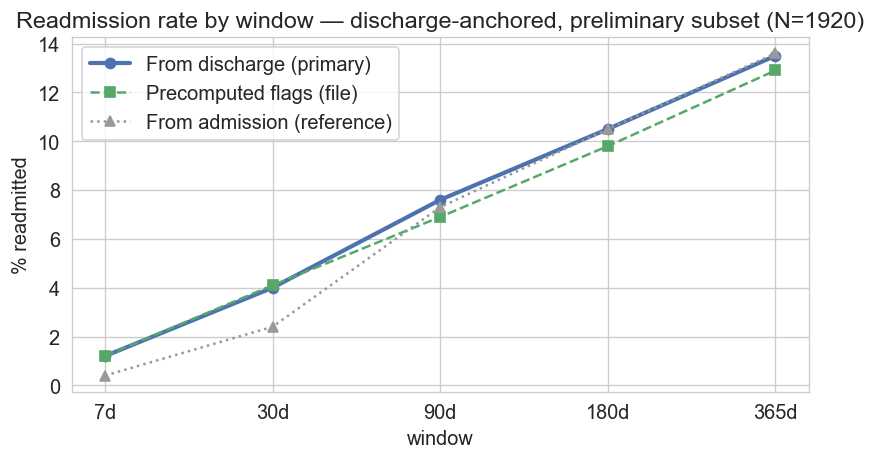

In [25]:
# Window ladder: from-admission vs from-discharge vs precomputed
def win_rate(days_col, w):
    return ((xl['has_readmit']==1)&(xl[days_col]>=0)&(xl[days_col]<=w)).mean()*100
WINS=[7,30,90,180,365]
ladder=pd.DataFrame({
 'from_discharge_%':[round(win_rate('days_to_readmit_dc',w),1) for w in WINS],          # PRIMARY (standard definition)
 'precomputed_%':[round(pd.to_numeric(xl[c],errors='coerce').fillna(0).mean()*100,1) for c in ['Readmit7Days','Readmit30Days','Readmit 90 days','Readmit 180 days','Readmit 365 days']],
 'from_admission_%':[round(win_rate('days_to_readmit_adm',w),1) for w in WINS],          # reference only
}, index=[f'{w}d' for w in WINS])
ladder.to_csv('figures/Win_rate_ladder.csv')
print('Readmission window ladder (PRELIMINARY SUBSET, N=%d) — PRIMARY = from discharge:'%NXL); print(ladder.to_string())
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(ladder.index, ladder['from_discharge_%'], marker='o', lw=2.5, color=BLUE, label='From discharge (primary)')
ax.plot(ladder.index, ladder['precomputed_%'], marker='s', ls='--', color=GREEN, label='Precomputed flags (file)')
ax.plot(ladder.index, ladder['from_admission_%'], marker='^', ls=':', color='0.6', label='From admission (reference)')
ax.set_ylabel('% readmitted'); ax.set_xlabel('window'); ax.legend()
ax.set_title('Readmission rate by window — discharge-anchored, preliminary subset (N=%d)'%NXL); plt.tight_layout(); plt.savefig('figures/Win_rate_ladder.png'); plt.show()

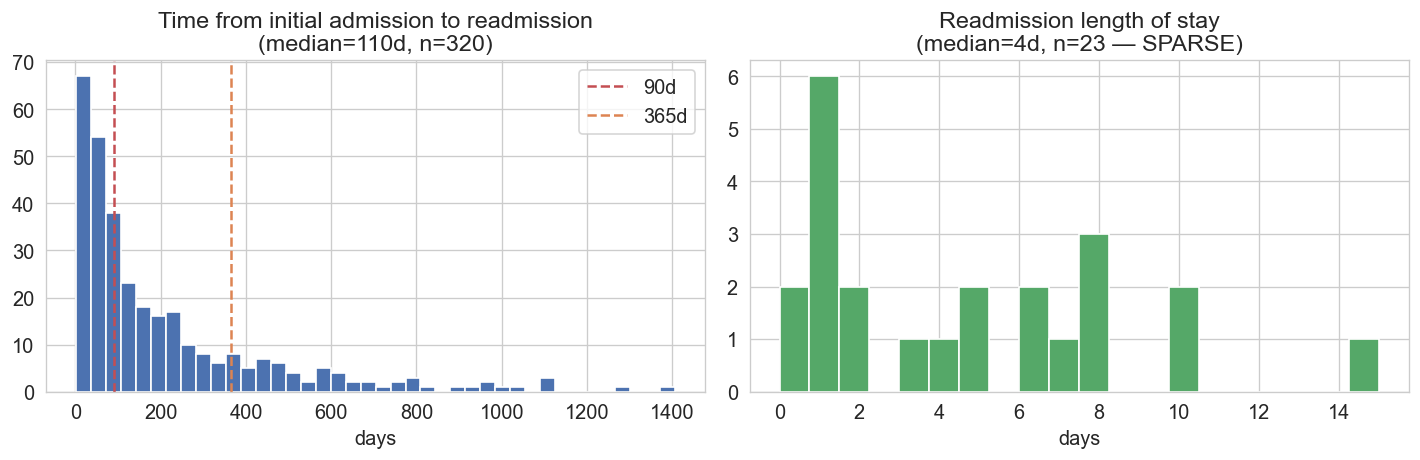

Time-to-readmit (from admission): median=110d (n=320); readmit LOS available n=23


In [26]:
# Time-to-readmission & readmission-LOS distributions (preliminary subset)
re_only=xl[xl.has_readmit==1]
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(re_only['days_to_readmit_adm'].dropna(),bins=40,color=BLUE); ax[0].axvline(90,color=RED,ls='--',label='90d'); ax[0].axvline(365,color=ORANGE,ls='--',label='365d')
ax[0].set_title(f'Time from initial admission to readmission\n(median={re_only.days_to_readmit_adm.median():.0f}d, n={re_only.days_to_readmit_adm.notna().sum()})'); ax[0].set_xlabel('days'); ax[0].legend()
rl=re_only['readmit_los'].dropna()
ax[1].hist(rl,bins=20,color=GREEN); ax[1].set_title(f'Readmission length of stay\n(median={rl.median():.0f}d, n={len(rl)} — SPARSE)'); ax[1].set_xlabel('days')
plt.tight_layout(); plt.savefig('figures/Win_distributions.png'); plt.show()
print(f'Time-to-readmit (from admission): median={re_only.days_to_readmit_adm.median():.0f}d (n={re_only.days_to_readmit_adm.notna().sum()}); readmit LOS available n={len(rl)}')

In [27]:
# Window rates by linked predictor (does ACE/restraint/diagnosis shift 90/365-day readmission?)
# Discharge-anchored (primary definition), consistent with the ladder above.
def wflag(w): return ((linked['has_readmit']==1)&(linked['days_to_readmit_dc']>=0)&(linked['days_to_readmit_dc']<=w)).astype(int)
linked['re90']=wflag(90); linked['re365']=wflag(365)
strat=[]
for name,mask in [('High ACE (expanded)',linked['high_ace_expanded']==1),('Not high ACE',linked['high_ace_expanded']==0),
                  ('Restrained',linked['had_restraints']==1),('No restraint',linked['had_restraints']==0),
                  ('Depression',linked['has_depression']==1),('ADHD',linked['has_adhd']==1)]:
    g=linked[mask]
    strat.append(dict(group=name,n=len(g),re90_pct=round(g['re90'].mean()*100,1),re365_pct=round(g['re365'].mean()*100,1)))
strat=pd.DataFrame(strat); strat.to_csv('figures/Win_by_predictor.csv',index=False)
print('90/365-day readmission by predictor (linked subset):'); print(strat.to_string(index=False))

90/365-day readmission by predictor (linked subset):
              group    n  re90_pct  re365_pct
High ACE (expanded)  843       7.6       12.7
       Not high ACE  480       6.9       12.1
         Restrained  199       7.5       14.6
       No restraint 1216       7.1       12.0
         Depression 1013       7.9       13.2
               ADHD  754       7.2       13.9


## §5 — Psychiatrist vs Nurse Practitioner (exploratory, preliminary subset)
**⚠ EXPLORATORY / UNDERPOWERED.** The provider field exists only in the preliminary XLSX, with
**1,894 psychiatrist vs 26 NP encounters**. Comparisons are descriptive with caveated tests; the
NP group is far too small for reliable inference.

PSYCHIATRIST vs NP (EXPLORATORY, n_NP=26 — underpowered):
        metric  Psychiatrist    NP         test     p
  n encounters       1894.00 26.00            —     —
LOS median (d)          8.00  9.00 Mann-Whitney 0.230
     Readmit %         16.80 15.40   chi-square 1.000
    CMI median          1.24  1.23 Mann-Whitney 0.910
    Age median         10.00 10.00 Mann-Whitney 0.149


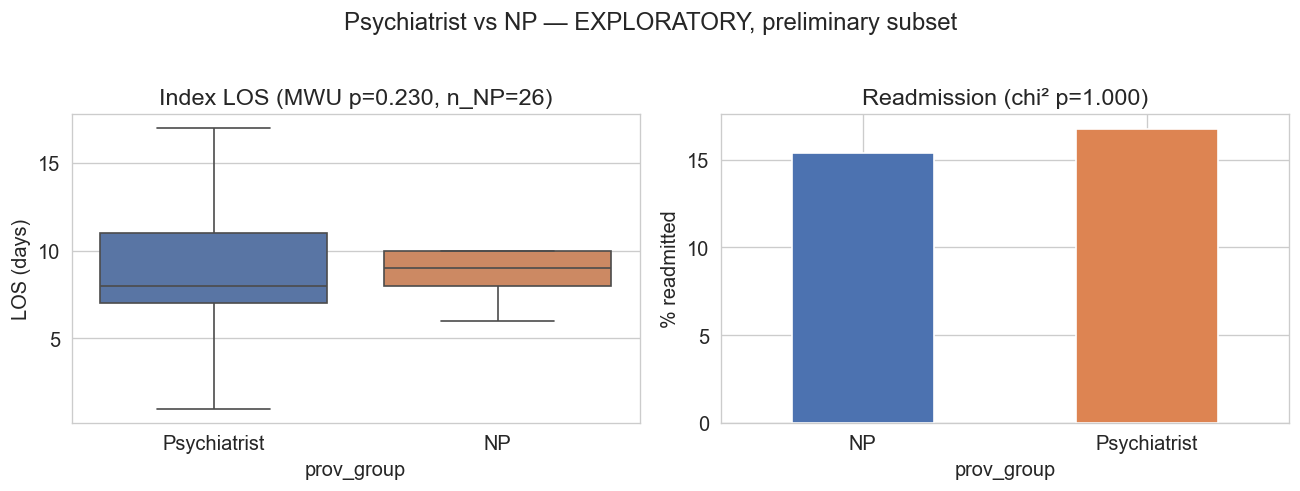

In [28]:
# Provider groups + comparisons
xl['prov_group']=xl['AttendingSpecialty'].apply(lambda s:'NP' if 'NP' in str(s).upper() else ('Psychiatrist' if 'PSYCH' in str(s).upper() else 'Other'))
g=xl[xl.prov_group.isin(['Psychiatrist','NP'])].copy()
psy,npg=g[g.prov_group=='Psychiatrist'],g[g.prov_group=='NP']
los_r=mwu(psy.index_los,npg.index_los)
re_tab=chi2(g.prov_group,g.has_readmit)
cmi_r=mwu(pd.to_numeric(psy.get('CMI'),errors='coerce'),pd.to_numeric(npg.get('CMI'),errors='coerce'))
age_r=mwu(pd.to_numeric(psy.get('AgeYears'),errors='coerce'),pd.to_numeric(npg.get('AgeYears'),errors='coerce'))
summary=pd.DataFrame([
 dict(metric='n encounters',Psychiatrist=len(psy),NP=len(npg),test='—',p='—'),
 dict(metric='LOS median (d)',Psychiatrist=round(los_r['med1'],1),NP=round(los_r['med2'],1),test='Mann-Whitney',p=pstr(los_r['p'])),
 dict(metric='Readmit %',Psychiatrist=round(psy.has_readmit.mean()*100,1),NP=round(npg.has_readmit.mean()*100,1),test='chi-square',p=pstr(re_tab['p'])),
 dict(metric='CMI median',Psychiatrist=round(cmi_r['med1'],2),NP=round(cmi_r['med2'],2),test='Mann-Whitney',p=pstr(cmi_r['p'])),
 dict(metric='Age median',Psychiatrist=round(age_r['med1'],1),NP=round(age_r['med2'],1),test='Mann-Whitney',p=pstr(age_r['p'])),
])
summary.to_csv('figures/Prov_comparison.csv',index=False)
print('PSYCHIATRIST vs NP (EXPLORATORY, n_NP=26 — underpowered):'); print(summary.to_string(index=False))
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.boxplot(data=g,x='prov_group',y='index_los',ax=ax[0],showfliers=False,palette=[BLUE,ORANGE]); ax[0].set_title(f'Index LOS (MWU p={pstr(los_r["p"])}, n_NP=26)'); ax[0].set_ylabel('LOS (days)')
g.groupby('prov_group')['has_readmit'].mean().mul(100).plot.bar(ax=ax[1],color=[BLUE,ORANGE]); ax[1].set_ylabel('% readmitted'); ax[1].set_title(f'Readmission (chi² p={pstr(re_tab["p"])})'); ax[1].tick_params(axis='x',rotation=0)
plt.suptitle('Psychiatrist vs NP — EXPLORATORY, preliminary subset',y=1.02); plt.tight_layout(); plt.savefig('figures/Prov_comparison.png'); plt.show()

## §6 — ML / predictive augmentation
Random Forest and CatBoost (vs logistic baseline) predicting **readmission**, using the established
features plus new ones (reclassified **neurocognitive** flag, restraint count, full DSM-5 category
set). Performance is reported **out-of-fold** (10-fold stratified CV) to avoid optimism; in-sample
tree AUCs are not trustworthy. A bootstrap test compares the augmented feature set to the baseline.

> Consistent with the project's documented predictive ceiling (out-of-fold AUC ≈ 0.68): these
> models characterize risk factors but cannot triage individuals.

In [29]:
# Build feature matrix (baseline + augmented) with imputation
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from catboost import CatBoostClassifier

# NOTE (ExtC §6): Same rationale as ML_A — individual DSM-5 flags are intentionally
# kept alongside n_dsm5_categories for ML prediction (AUC). This is correct for
# prediction context; the inferential ExtB model (§3) uses n_dsm5_categories only.
BASE_FEATS = ['age','gender_male','insurance_public','had_restraints','csrss_any','los_days',
              'n_dsm5_categories','has_depression','has_trauma','has_adhd','has_nssi',
              'has_asd','has_conduct','has_bipolar','has_psychotic']
NEW_FEATS  = ['restraint_n','has_neurocognitive','has_suicidal_ideation','has_anxiety','has_intellectual','has_ocd','high_ace_expanded']
ALL_FEATS  = BASE_FEATS + NEW_FEATS

Xa = df[ALL_FEATS].copy()
imp = IterativeImputer(estimator=RandomForestRegressor(n_estimators=50,random_state=42),max_iter=10,random_state=42)
Xa[['age','los_days']] = imp.fit_transform(Xa[['age','los_days']])
Xa = Xa.fillna(0)
yv = df['readmitted'].values
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
print(f'Feature matrix: {Xa.shape}; readmit prevalence={yv.mean():.1%}; {len(BASE_FEATS)} base + {len(NEW_FEATS)} new feats')

Feature matrix: (2652, 22); readmit prevalence=9.3%; 15 base + 7 new feats


Logistic       OOF AUC=0.683  AP=0.178
RandomForest   OOF AUC=0.695  AP=0.180
CatBoost       OOF AUC=0.656  AP=0.161


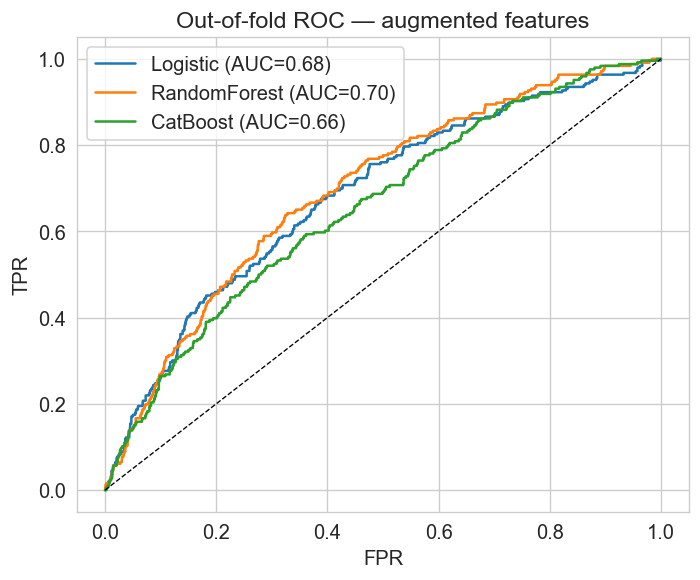

In [30]:
# Out-of-fold AUC/AP for LR, RF, CatBoost (augmented feature set)
def oof(model, X):
    p = cross_val_predict(model, X, yv, cv=cv, method='predict_proba', n_jobs=-1)[:,1]
    return p, roc_auc_score(yv,p), average_precision_score(yv,p)
models = {
 'Logistic': LogisticRegression(max_iter=2000, class_weight='balanced'),
 'RandomForest': RandomForestClassifier(n_estimators=400,max_depth=6,min_samples_leaf=10,class_weight='balanced',random_state=42,n_jobs=-1),
 'CatBoost': CatBoostClassifier(iterations=400,depth=6,learning_rate=0.05,loss_function='Logloss',random_state=42,verbose=False),
}
perf={}; probs={}
for name,mdl in models.items():
    Xs = StandardScaler().fit_transform(Xa) if name=='Logistic' else Xa.values
    p,auc,ap = oof(mdl, Xs); perf[name]=(auc,ap); probs[name]=p
    print(f'{name:14s} OOF AUC={auc:.3f}  AP={ap:.3f}')
perf_df=pd.DataFrame(perf,index=['AUC','AP']).T; perf_df.to_csv('figures/MLx_oof_performance.csv')
fig,ax=plt.subplots(figsize=(6,5))
for name,p in probs.items():
    fpr,tpr,_=roc_curve(yv,p); ax.plot(fpr,tpr,label=f'{name} (AUC={perf[name][0]:.2f})')
ax.plot([0,1],[0,1],'k--',lw=.8); ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.legend()
ax.set_title('Out-of-fold ROC — augmented features'); plt.tight_layout(); plt.savefig('figures/MLx_roc.png'); plt.show()

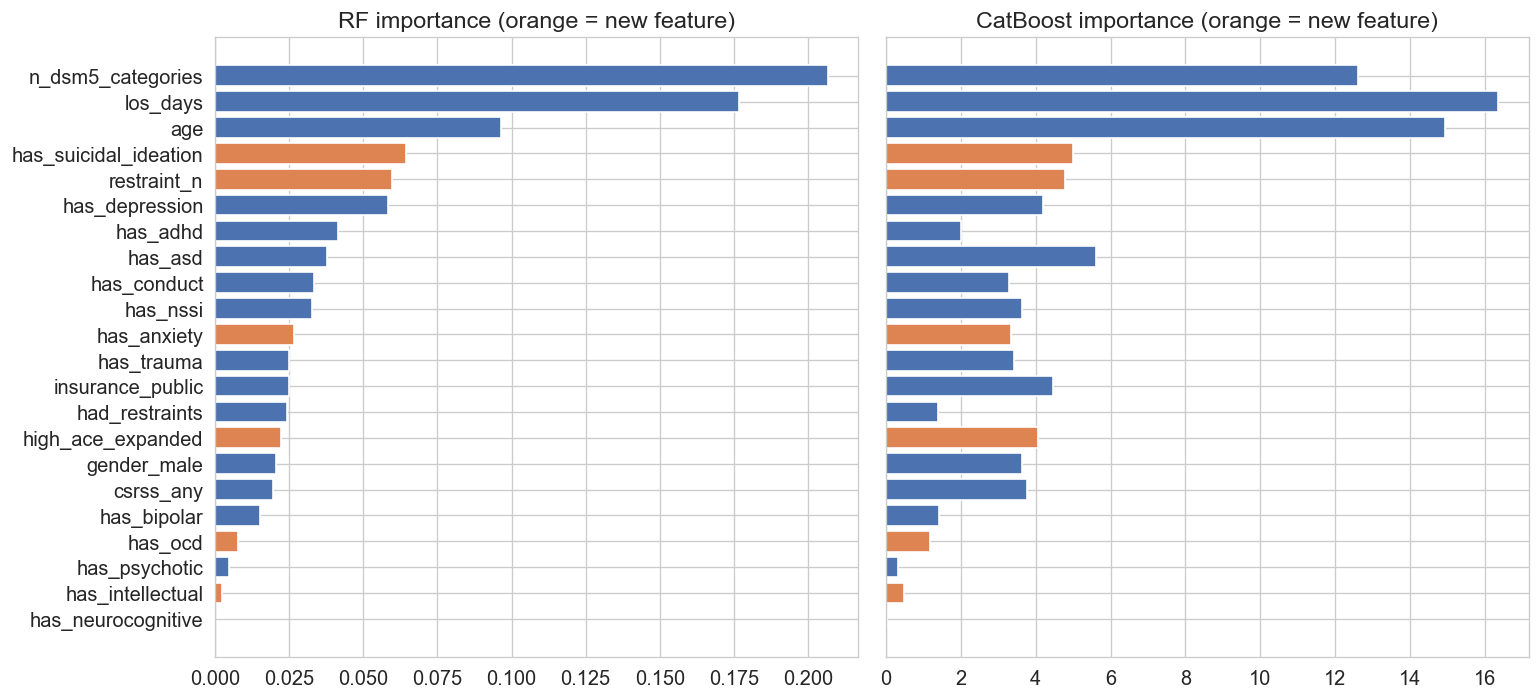

                          RF  CatBoost  is_new
feature                                       
n_dsm5_categories      0.207    12.609   False
los_days               0.177    16.342   False
age                    0.096    14.934   False
has_suicidal_ideation  0.064     4.989    True
restraint_n            0.060     4.797    True
has_depression         0.058     4.202   False
has_adhd               0.042     2.009   False
has_asd                0.038     5.615   False
has_conduct            0.033     3.284   False
has_nssi               0.033     3.637   False
has_anxiety            0.027     3.339    True
has_trauma             0.025     3.412   False
insurance_public       0.025     4.472   False
had_restraints         0.024     1.409   False
high_ace_expanded      0.022     4.067    True
gender_male            0.021     3.641   False
csrss_any              0.019     3.766   False
has_bipolar            0.015     1.436   False
has_ocd                0.008     1.184    True
has_psychotic

In [31]:
# Feature importance: RF + CatBoost (fit on full data)
rf=RandomForestClassifier(n_estimators=400,max_depth=6,min_samples_leaf=10,class_weight='balanced',random_state=42,n_jobs=-1).fit(Xa,yv)
cb=CatBoostClassifier(iterations=400,depth=6,learning_rate=0.05,random_state=42,verbose=False).fit(Xa,yv)
imp_df=pd.DataFrame({'feature':ALL_FEATS,'RF':rf.feature_importances_,'CatBoost':cb.feature_importances_}).set_index('feature')
imp_df['is_new']=[f in NEW_FEATS for f in imp_df.index]
imp_df.to_csv('figures/MLx_feature_importance.csv')
fig,ax=plt.subplots(1,2,figsize=(13,6),sharey=True)
for a,col in zip(ax,['RF','CatBoost']):
    s=imp_df[col].sort_values()
    a.barh(s.index, s.values, color=[ORANGE if imp_df.loc[f,'is_new'] else BLUE for f in s.index])
    a.set_title(f'{col} importance (orange = new feature)')
plt.tight_layout(); plt.savefig('figures/MLx_feature_importance.png'); plt.show()
print(imp_df.sort_values('RF',ascending=False).round(3).to_string())

In [32]:
# SHAP summary (RandomForest) — robust to failure
try:
    import shap
    expl=shap.TreeExplainer(rf)
    samp=Xa.sample(min(400,len(Xa)),random_state=42)
    sv=expl.shap_values(samp)
    sv1=sv[1] if isinstance(sv,list) else sv
    plt.figure(); shap.summary_plot(sv1, samp, show=False, max_display=15)
    plt.title('SHAP summary — Random Forest (readmission)'); plt.tight_layout(); plt.savefig('figures/MLx_shap_rf.png',bbox_inches='tight'); plt.close()
    print('✓ SHAP summary saved → figures/MLx_shap_rf.png')
except Exception as e:
    print('SHAP skipped:', str(e)[:100])

✓ SHAP summary saved → figures/MLx_shap_rf.png


<Figure size 768x576 with 0 Axes>

In [33]:
# Bootstrap: does the augmented feature set beat the baseline (RF, OOF AUC)?
def oof_auc(cols):
    Xm=Xa[cols].values
    p=cross_val_predict(RandomForestClassifier(n_estimators=400,max_depth=6,min_samples_leaf=10,class_weight='balanced',random_state=42,n_jobs=-1),Xm,yv,cv=cv,method='predict_proba',n_jobs=-1)[:,1]
    return p
p_base=oof_auc(BASE_FEATS); p_aug=oof_auc(ALL_FEATS)
auc_base,auc_aug=roc_auc_score(yv,p_base),roc_auc_score(yv,p_aug)
rng=np.random.RandomState(42); diffs=[]
idx=np.arange(len(yv))
for _ in range(2000):
    b=rng.choice(idx,len(idx),replace=True)
    if yv[b].sum()<5: continue
    diffs.append(roc_auc_score(yv[b],p_aug[b])-roc_auc_score(yv[b],p_base[b]))
diffs=np.array(diffs); lo,hi=np.percentile(diffs,[2.5,97.5]); pval=2*min((diffs<=0).mean(),(diffs>=0).mean())
print(f'Baseline RF OOF AUC={auc_base:.3f} | Augmented={auc_aug:.3f} | Δ={auc_aug-auc_base:+.3f} (95% CI {lo:+.3f},{hi:+.3f}), bootstrap p={pstr(pval)}')
print('Interpretation: new features add little discrimination — consistent with the ~0.68 predictive ceiling.')

Baseline RF OOF AUC=0.685 | Augmented=0.695 | Δ=+0.010 (95% CI -0.005,+0.024), bootstrap p=0.179
Interpretation: new features add little discrimination — consistent with the ~0.68 predictive ceiling.


## §7 — Self-harm spectrum & systematic individual-ICD-code analysis
Earlier tiers worked at the DSM-5 *category* and ICD *chapter* level, which can dilute high-risk
individual codes. This section (a) separates the **self-harm spectrum** (ideation vs attempt vs
history) instead of merging it into one "suicidality" variable, and (b) sweeps **every ICD-10 code with
n≥30** to surface individual codes the category view hides — including a flag for codes that are
significant individually but whose DSM-5 category is not.

Self-harm spectrum (ICD codes) — distinct constructs, NOT one "suicidality" variable:
                                    measure    n  readmit_with  readmit_without  uni_OR  uni_p  adj_OR adj_p  LOS_p
                Suicidal ideation (R45.851) 1346          11.4              7.1    1.67 <0.001    1.47 0.010 <0.001
Suicide attempt / self-harm injury (T14.91)  119          10.1              9.2    1.14  0.669    1.34 0.370  0.051
               History of self-harm (Z91.5)   42          21.4              9.1    2.83  0.005    2.82 0.010  0.035
      Any attempt or history (T14.91/Z91.5)  154          12.3              9.1    1.44  0.150    1.67 0.059      —


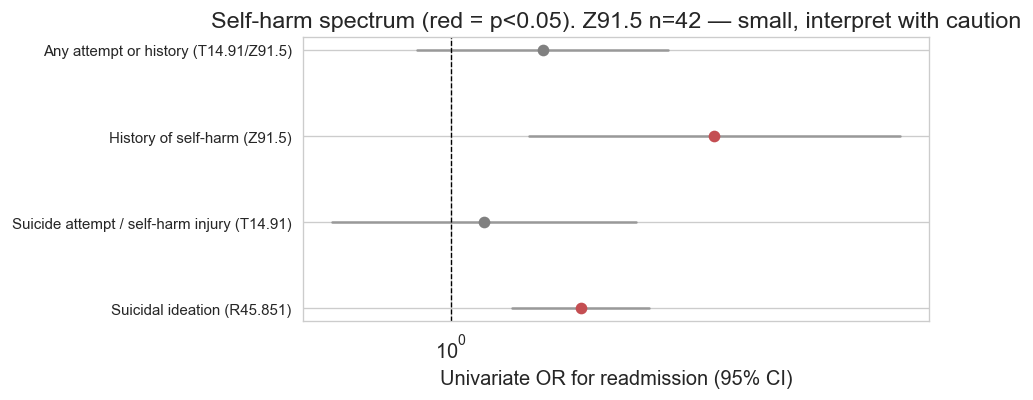


Key point: history of self-harm (Z91.5) carries the strongest signal but is rare (n=42);
ideation (R45.851) is common and moderate; a documented attempt code (T14.91) is not significant here.


In [34]:
# §7A — Self-harm / suicidality spectrum: ideation vs attempt vs history (univariate + adjusted)
from statsmodels.stats.contingency_tables import Table2x2
def _hald_or(flag):
    a=int(((flag==1)&(df.readmitted==1)).sum()); b=int(((flag==1)&(df.readmitted==0)).sum())
    c=int(((flag==0)&(df.readmitted==1)).sum()); e=int(((flag==0)&(df.readmitted==0)).sum())
    t=Table2x2(np.array([[a+0.5,b+0.5],[c+0.5,e+0.5]])); ci=t.oddsratio_confint()
    return t.oddsratio, ci[0], ci[1], t.oddsratio_pvalue()
_BASE='readmitted ~ age+gender_male+insurance_public+had_restraints+csrss_any+los_days+n_dsm5_categories+has_depression'
_spec={'Suicidal ideation (R45.851)':'R45.851','Suicide attempt / self-harm injury (T14.91)':'T14.91','History of self-harm (Z91.5)':'Z91.5'}
rows=[]
for lbl,code in _spec.items():
    df['_f']=allcodes.str.contains(code,regex=False).astype(int)
    orr,lo,hi,p=_hald_or(df['_f']); m=smf.logit(_BASE+' + _f',data=df).fit(disp=0,maxiter=200)
    losp=mwu(df[df._f==1].los_days, df[df._f==0].los_days)['p']
    rows.append(dict(measure=lbl,n=int(df._f.sum()),readmit_with=round(df[df._f==1].readmitted.mean()*100,1),
        readmit_without=round(df[df._f==0].readmitted.mean()*100,1),uni_OR=round(orr,2),lo=lo,hi=hi,uni_p=pstr(p),
        adj_OR=round(np.exp(m.params['_f']),2),adj_p=pstr(m.pvalues['_f']),LOS_p=pstr(losp)))
df['_f']=(allcodes.str.contains('T14.91',regex=False)|allcodes.str.contains('Z91.5',regex=False)).astype(int)
orr,lo,hi,p=_hald_or(df['_f']); m=smf.logit(_BASE+' + _f',data=df).fit(disp=0,maxiter=200)
rows.append(dict(measure='Any attempt or history (T14.91/Z91.5)',n=int(df._f.sum()),readmit_with=round(df[df._f==1].readmitted.mean()*100,1),
    readmit_without=round(df[df._f==0].readmitted.mean()*100,1),uni_OR=round(orr,2),lo=lo,hi=hi,uni_p=pstr(p),
    adj_OR=round(np.exp(m.params['_f']),2),adj_p=pstr(m.pvalues['_f']),LOS_p='—'))
spec_df=pd.DataFrame(rows); spec_df.drop(columns=['lo','hi']).to_csv('figures/Spectrum_selfharm.csv',index=False)
print('Self-harm spectrum (ICD codes) — distinct constructs, NOT one "suicidality" variable:')
print(spec_df.drop(columns=['lo','hi']).to_string(index=False))
fig,ax=plt.subplots(figsize=(8,3.5)); yy=range(len(spec_df))
for i,r in spec_df.iterrows():
    cc=RED if ('<' in str(r['uni_p']) or float(str(r['uni_p']).replace('<','')) < 0.05) else '0.5'
    ax.plot([r['lo'],r['hi']],[i,i],color='0.6'); ax.plot(r['uni_OR'],i,'o',color=cc)
ax.set_yticks(list(yy)); ax.set_yticklabels(spec_df['measure'],fontsize=9); ax.axvline(1,color='k',ls='--',lw=.8); ax.set_xscale('log')
ax.set_xlabel('Univariate OR for readmission (95% CI)'); ax.set_title('Self-harm spectrum (red = p<0.05). Z91.5 n=42 — small, interpret with caution')
plt.tight_layout(); plt.savefig('figures/Spectrum_selfharm.png'); plt.show()
print('\nKey point: history of self-harm (Z91.5) carries the strongest signal but is rare (n=42);')
print('ideation (R45.851) is common and moderate; a documented attempt code (T14.91) is not significant here.')

Individual codes tested (n>=30): 115; FDR-significant: 19  (descriptions from the ICD->DSM5 mapping file)

Top elevated-risk individual codes (FDR<0.05):
   code    n  readmit_pct    OR    p_fdr                                                      description
  F94.1   92         22.8 3.114 0.000254       Reactive attachment disorder of infancy or early childhood
 R45.88   42         21.4 2.834 0.032240               Other symptoms and signs involving emotional state
  Z91.5   42         21.4 2.834 0.032240                                    Personal history of self-harm
 R06.83   52         21.2 2.783 0.021512                                                            Apnea
Z62.812   70         20.0 2.595 0.015449             Personal history of psychological abuse in childhood
  P04.9  102         19.6 2.550 0.003339               Newborn affected by maternal unspecified condition
  F32.A   69         18.8 2.405 0.031931 Major depressive disorder, single episode, with anxious distres

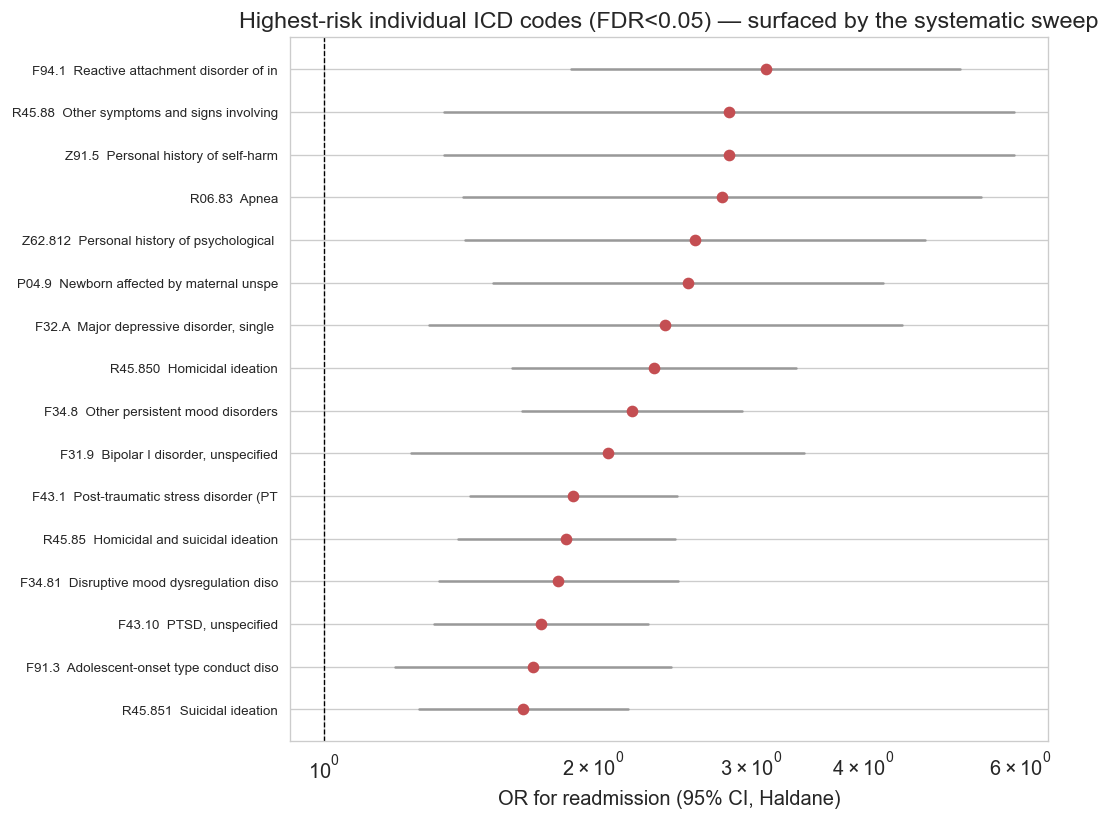

In [35]:
# §7B — Systematic individual-ICD-code sweep (all codes with n>=30) vs readmission
from collections import Counter
_cnt=Counter(t.strip() for s in allcodes for t in s.split(',') if t.strip())
_ref=pd.read_csv('data/ICD10_to_DSM5_Complete_Reference.csv').set_index('ICD_Code')
_desc=_ref['Description'].to_dict(); _dsm=_ref['DSM5_Category'].to_dict()
_desc.update({'Z91.5':'Personal history of self-harm'})   # mapping-file mislabels Z91.5 as 'noncompliance'
rows=[]
for c,n in _cnt.items():
    if n<30: continue
    f=allcodes.str.contains(c,regex=False).astype(int)
    if f.sum()<30: continue
    orr,lo,hi,p=_hald_or(f)
    rows.append(dict(code=c,n=int(f.sum()),readmit_pct=round(df[f==1].readmitted.mean()*100,1),OR=round(orr,3),lo=round(lo,3),hi=round(hi,3),p=p,
                     description=str(_desc.get(c,'')),dsm5_category=str(_dsm.get(c,''))))
sweep=pd.DataFrame(rows); sweep['p_fdr']=multipletests(sweep['p'],method='fdr_bh')[1]; sweep=sweep.sort_values('OR',ascending=False)
sweep.to_csv('figures/Code_sweep_readmission.csv',index=False)
sig=sweep[sweep['p_fdr']<0.05]
print(f'Individual codes tested (n>=30): {len(sweep)}; FDR-significant: {len(sig)}  (descriptions from the ICD->DSM5 mapping file)')
print('\nTop elevated-risk individual codes (FDR<0.05):')
print(sig.head(14)[['code','n','readmit_pct','OR','p_fdr','description']].to_string(index=False))
prot=sig[sig['OR']<1]
print(f'\nFDR-significant PROTECTIVE codes (OR<1): {len(prot)}' + ('' if len(prot) else ' — none; lowest significant ORs are still >1 (1.5-1.8 range).'))
# forest of top 16 by |log OR|
top=sig.reindex(sig['OR'].sort_values(ascending=False).index).head(16).iloc[::-1]
fig,ax=plt.subplots(figsize=(9,7)); yy=range(len(top))
for i,(_,r) in enumerate(top.iterrows()):
    ax.plot([r['lo'],r['hi']],[i,i],color='0.6'); ax.plot(r['OR'],i,'o',color=RED)
ax.set_yticks(list(yy)); ax.set_yticklabels([f"{r['code']}  {str(r['description'])[:34]}" for _,r in top.iterrows()],fontsize=8)
ax.axvline(1,color='k',ls='--',lw=.8); ax.set_xscale('log'); ax.set_xlabel('OR for readmission (95% CI, Haldane)')
ax.set_title('Highest-risk individual ICD codes (FDR<0.05) — surfaced by the systematic sweep')
plt.tight_layout(); plt.savefig('figures/Code_sweep_readmission.png'); plt.show()

In [36]:
# §7B (cont.) — LOST NUANCES: codes significant individually but whose DSM-5 category is NOT
catp={}
for cat in sweep['dsm5_category'].dropna().unique():
    if not str(cat).strip(): continue
    cf=all_dsm5.str.contains(str(cat).lower(),na=False).astype(int)
    if cf.sum()<30: continue
    catp[cat]=_hald_or(cf)[3]
lost=[]
for _,r in sig.iterrows():
    cat=r['dsm5_category']
    if cat and str(cat).strip() and cat in catp and catp[cat]>=0.05:
        lost.append(dict(code=r['code'],OR=r['OR'],description=r['description'][:40],dsm5_category=cat,category_p=round(catp[cat],3)))
lost_df=pd.DataFrame(lost); lost_df.to_csv('figures/Code_lost_nuances.csv',index=False)
print('LOST NUANCES — individually FDR-significant codes whose DSM-5 *category* is non-significant')
print('(these high-risk codes are diluted when collapsed to the category level):')
print(lost_df.to_string(index=False) if len(lost_df) else '  (none)')
# LOS sweep
rowsl=[]
for c,n in _cnt.items():
    if n<30: continue
    f=allcodes.str.contains(c,regex=False)
    if f.sum()<30: continue
    r=mwu(df[f].los_days, df[~f].los_days)
    rowsl.append(dict(code=c,n=int(f.sum()),median_with=r['med1'],median_without=r['med2'],dLOS=r['med1']-r['med2'],p=r['p'],description=str(_desc.get(c,''))))
losdf=pd.DataFrame(rowsl); losdf['p_fdr']=multipletests(losdf['p'].fillna(1),method='fdr_bh')[1]
losdf.sort_values('dLOS',ascending=False).to_csv('figures/Code_sweep_los.csv',index=False)
ls=losdf[losdf.p_fdr<0.05].sort_values('dLOS',ascending=False)
print(f'\nIndividual codes with FDR-significant LOS difference: {len(ls)}. Top longer-LOS:')
print(ls.head(8)[['code','n','dLOS','p_fdr','description']].to_string(index=False))

LOST NUANCES — individually FDR-significant codes whose DSM-5 *category* is non-significant
(these high-risk codes are diluted when collapsed to the category level):
   code    OR                              description                         dsm5_category  category_p
  F94.1 3.114 Reactive attachment disorder of infancy  Trauma and Stressor-Related Disorders       0.063
  F43.1 1.898    Post-traumatic stress disorder (PTSD) Trauma and Stressor-Related Disorders       0.063
 F43.10 1.748                        PTSD, unspecified Trauma and Stressor-Related Disorders       0.063
R45.851 1.669                        Suicidal ideation     Non-Suicidal Self-Injury Behavior       0.188

Individual codes with FDR-significant LOS difference: 35. Top longer-LOS:
  code   n  dLOS    p_fdr                                                description
 F91.1  34   2.5 0.008096                      Childhood-onset type conduct disorder
 K21.9  66   2.0 0.013846       Gastro-esophageal reflux disease

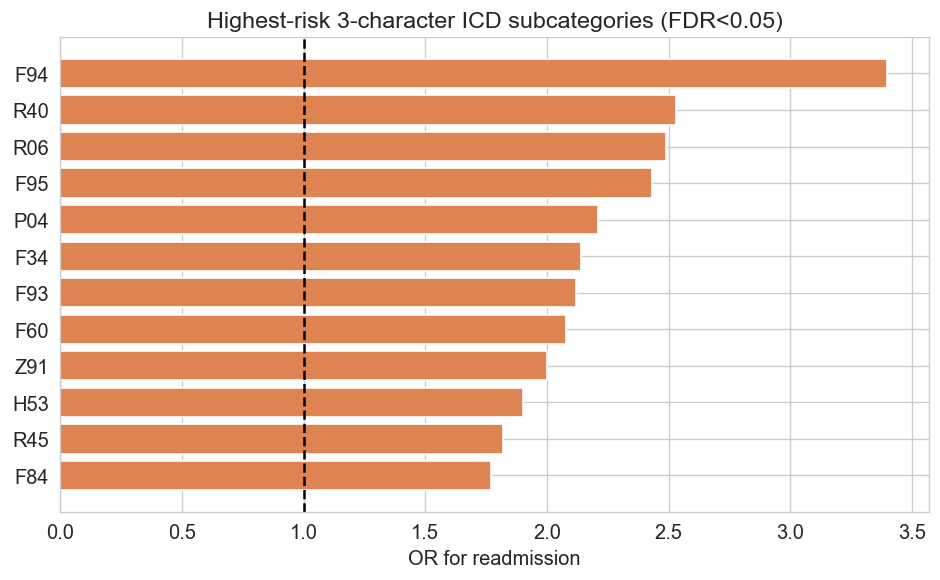

Top 3-char ICD subcategories by readmission OR (FDR<0.05):
prefix    n  readmit_pct   OR            p    p_fdr
   F94   99         24.2 3.40 4.672577e-07 0.000020
   R40   51         19.6 2.53 8.367863e-03 0.046860
   R06   62         19.4 2.49 4.817817e-03 0.031131
   F95   79         19.0 2.43 2.273522e-03 0.021220
   P04  126         17.5 2.21 1.097937e-03 0.011528
   F34  538         15.2 2.14 1.353941e-07 0.000011
   F93  161         16.8 2.12 6.866474e-04 0.008240
   F60  120         16.7 2.08 3.742238e-03 0.026196
   Z91  149         16.1 2.00 2.749160e-03 0.023093
   H53  142         15.5 1.90 7.419895e-03 0.044519
   R45 1557         11.2 1.82 4.292282e-05 0.001202
   F84  513         13.6 1.77 1.500960e-04 0.002522


In [37]:
# §7C — 3-character ICD subcategory layer (between chapter and individual code)
from collections import Counter
_p3=Counter()
for s in allcodes:
    for t in {x.strip()[:3] for x in s.split(',') if x.strip()}: _p3[t]+=1
rows=[]
for p3,n in _p3.items():
    if n<30: continue
    f=allcodes.apply(lambda s: any(x.strip().startswith(p3) for x in s.split(','))).astype(int)
    orr,lo,hi,p=_hald_or(f); rows.append(dict(prefix=p3,n=int(f.sum()),readmit_pct=round(df[f==1].readmitted.mean()*100,1),OR=round(orr,2),p=p))
sub3=pd.DataFrame(rows); sub3['p_fdr']=multipletests(sub3['p'],method='fdr_bh')[1]
sub3=sub3.sort_values('OR',ascending=False); sub3.to_csv('figures/Code_subcat3.csv',index=False)
topc=sub3[sub3.p_fdr<0.05].head(12)
fig,ax=plt.subplots(figsize=(8,5)); ax.barh(topc['prefix'][::-1],topc['OR'][::-1],color=ORANGE); ax.axvline(1,color='k',ls='--')
ax.set_xlabel('OR for readmission'); ax.set_title('Highest-risk 3-character ICD subcategories (FDR<0.05)')
plt.tight_layout(); plt.savefig('figures/Code_subcat3.png'); plt.show()
print('Top 3-char ICD subcategories by readmission OR (FDR<0.05):'); print(topc.to_string(index=False))